# Prosody-Syntax Distributional Analysis

This notebook builds a co-occurrence matrix of (lemma, POS) tags against a mix of
**syntactic** and **prosodic** features extracted from the SUD-French-Rhapsodie
treebank. From that matrix we derive three parallel views — syntactic-only,
prosodic-only, and combined — and use each to compute:

1. **Similarity scores** between lexical units
2. A **per-unit purity / entropy / rival-category** score
3. A **category-level transition matrix** (how categories bleed into each other)
4. **Bridge words** — units whose neighbourhood pulls them toward a different POS
5. **Pulling features** — the features responsible for that pull
6. A global **weighted-average stability** for each feature space: syntactic, prosodic or both

The key cleanup vs. the original notebook: every downstream analysis takes a
`space` selector ∈ `{"syntactic", "prosodic", "combined",
"prosodic_foot", "prosodic_group", "prosodic_package", "prosodic_period",
"prosodic_all_levels"}`, so swapping feature
spaces is a one-line change.

In [1]:
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

from scipy.stats import entropy
from sklearn.metrics.pairwise import cosine_similarity

# ── Paths ──────────────────────────────────────────────────────────────────
TOD_PATH      = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/tod"
GREX_PATH     = "/Users/madalina/Documents/M2TAL/stage/grex/grex2"
TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_pauses"
# TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/pSUD_Naija-NSC"
PATTERNS_FILE = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/3. probability_matrix/patterns_all_nodes_prosody.txt"

GREW_PATTERN      = "pattern{X[upos<>PUNCT]}"
ANALYSED_CATEGORY = "all_nodes"   # kept for reference; not used downstream

# ── Bring third-party packages onto the path ───────────────────────────────
for p in (TOD_PATH, GREX_PATH):
    if p not in sys.path:
        sys.path.insert(1, p)

import pyximport
pyximport.install()

import grewpy
from grewpy import Corpus, CorpusDraft, Request

import tod.corpus  # noqa: F401  (registers handlers; keep import)

import grex.data           # noqa: F401
import grex.utils
import grex.features       # noqa: F401
import grex.data_prosody

grewpy.set_config("sud")


connected to port: 62208


In [2]:
# ── Drop entirely: redundant, unreliable, or too fine-grained ─────────────
FEATURES_TO_DROP = {
    'MeanF0',           # use SemitonesFromUtteranceMean instead (speaker-normalised)
    'MeanF0Step',       # threshold artefact, not a prosodic observation
    'AvgAmplitude',     # recording-condition-dependent
    'MaxAmplitude',     # same
    'SylForm',          # phonetic transcription, too fine-grained
    'AlignBegin',       # timing offset, not linguistic
    'AlignEnd',         # timing offset, not linguistic
    'pauseID',          # identifier, not a feature
    # Before*/Next* equivalents of dropped features:
    'BeforeMeanF0', 'BeforeMeanF0Step', 'BeforeAvgAmplitude',
    'NextMeanF0',   'NextMeanF0Step',   'NextAvgAmplitude',
    'Semiton', 'Overlap', 'Loc', 'Glo', 'Backchannel',
    "AvgAmplitudeNormalized", "Nucleus", "Onset", "MeanF0GlobalZscore", "MeanF0LocalZscore", "MeanF0Normalized"
}

# ── Bin into 3 quantile-based categories ──────────────────────────────────
# Note: Duration appears in TWO units in the data:
#   - syllable subnodes: integer ms     (e.g. 289, 167)
#   - pause nodes:       float seconds  (e.g. 0.2695, 0.3328)
# We normalise to ms before binning — see `_normalise_duration` below.
FEATURES_TO_BIN = {
    'SemitonesFromUtteranceMean',
    'Duration',
    'BeforeSemitonesFromUtterance',
    'NextSemitonesFromUtterance',
    'BeforeDuration',
    'NextDuration',
    'BeforeSemiton',
    'NextSemiton',
    'NextSemitonsFromUtterance',
    'AvgAmplitudeGlobalZscore', # naija
    # naija
    "DurationGlobalZscore" # naija
}

BIN_LABELS = {
    'SemitonesFromUtteranceMean':   ['F0_low',       'F0_mid',       'F0_high'],
    'Duration':                     ['Dur_short',    'Dur_mid',      'Dur_long'],
    'BeforeSemitonesFromUtterance': ['BeforeF0_low', 'BeforeF0_mid', 'BeforeF0_high'],
    'NextSemitonesFromUtterance':   ['NextF0_low',   'NextF0_mid',   'NextF0_high'],
}


In [3]:
# ── SLAM3 contour decomposition ───────────────────────────────────────────
# The *Tone features (FootTone, GroupTone, PackageTone, Period_tone) encode
# pitch contours compositionally:
#
#     [start_pitch][end_pitch]            -- no salient peak (2 chars)
#     [start_pitch][end_pitch][peak][tier] -- with salient peak (4 chars)
#
# pitch ∈ {L, l, m, h, H}  (5 ordinal levels: very low → very high)
# tier  ∈ {1, 2, 3}        (which syllabic tier carries the peak)
# Plus the special atomic value 'Pause'.
#
# Treating these as opaque strings gives ~300 sparse one-hot columns per
# *Tone feature. Decomposing into {start, end, peak, tier, has_peak,
# direction, magnitude} yields ~5 dense sub-features per token instead.

SLAM_TONE_FEATURES = {'FootTone', 'GroupTone', 'PackageTone', 'Period_tone'}

# Ordinal mapping used to derive direction & magnitude.
_PITCH_LEVELS = {'L': 1, 'l': 2, 'm': 3, 'h': 4, 'H': 5}
_TIERS = {'1', '2', '3'}


def _parse_slam(label):
    """Parse a SLAM3 contour string into its components.

    Returns a dict {pause, start, end, peak, tier} or None if the label
    doesn't match the SLAM3 grammar (silently skipped downstream).
    """
    if label == 'Pause':
        return {'pause': True, 'start': None, 'end': None,
                'peak': None, 'tier': None}

    if (len(label) == 2
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': None, 'tier': None}

    if (len(label) == 4
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS
            and label[2] in _PITCH_LEVELS and label[3] in _TIERS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': label[2], 'tier': label[3]}

    return None


def _slam_subfeatures(prefix, label):
    """Yield 'sub-feature=value' strings derived from a SLAM3 contour label.

    `prefix` is the path up to and including the *Tone name,
    e.g. 'node:X:child:GroupTone'. Sub-features become
    'node:X:child:GroupTone:start=H', 'node:X:child:GroupTone:direction=rise', …
    """
    parsed = _parse_slam(label)
    if parsed is None:
        return

    if parsed['pause']:
        yield f"{prefix}:pause=True"
        return

    s, e = parsed['start'], parsed['end']
    yield f"{prefix}:start={s}"
    yield f"{prefix}:end={e}"

    # Direction & magnitude on the ordinal pitch scale.
    delta = _PITCH_LEVELS[e] - _PITCH_LEVELS[s]
    if delta > 0:
        direction = 'rise'
    elif delta < 0:
        direction = 'fall'
    else:
        direction = 'flat'
    yield f"{prefix}:direction={direction}"
    yield f"{prefix}:magnitude={abs(delta)}"

    if parsed['peak'] is not None:
        yield f"{prefix}:has_peak=True"
        yield f"{prefix}:peak={parsed['peak']}"
        yield f"{prefix}:tier={parsed['tier']}"
    else:
        yield f"{prefix}:has_peak=False"

In [4]:
def _normalise_duration(value_str):
    """Convert a Duration string to milliseconds regardless of source node type.

    Syllable subnodes store ms (e.g. '289'); pause nodes store seconds
    (e.g. '0.2695'). Heuristic: values < 10 are seconds. A literal 0.0 means
    'missing' (e.g. overlap nodes) → returns None.
    """
    try:
        v = float(value_str)
    except (ValueError, TypeError):
        return None
    if v == 0.0:
        return None
    return v * 1000 if v < 10 else v


def _is_sentinel(value_str):
    """True for the '0.0' sentinel that overlap / missing pause nodes carry.

    Without this guard, those zeros would be binned as F0_low rather than
    silently dropped.
    """
    try:
        return float(value_str) == 0.0
    except (ValueError, TypeError):
        return False


def _feature_name(key):
    """Bare feature name from a path-like key, e.g. ('node','X','child','Duration') → 'Duration'."""
    return key[-1]


In [5]:
def collect_continuous_values(all_data_items):
    """Walk every (lex_unit, match, features) triple and collect raw float
    values for each feature in FEATURES_TO_BIN.

    Returns: {feature_name: [float, ...]}
    """
    collector = {f: [] for f in FEATURES_TO_BIN}

    for _, _, features in all_data_items:
        for key, value in features.items():
            fname = _feature_name(key)
            if fname not in FEATURES_TO_BIN:
                continue
            # `value` is a string for own/parent/prev/next, or a set of strings
            # for child (a node can have multiple syllables).
            values = value if isinstance(value, set) else {value}
            for v in values:
                if fname == 'Duration':
                    norm = _normalise_duration(v)
                    if norm is not None:
                        collector['Duration'].append(norm)
                elif not _is_sentinel(v):
                    try:
                        collector[fname].append(float(v))
                    except (ValueError, TypeError):
                        pass
    return collector


def compute_thresholds(collector, n_bins=3):
    """Quantile boundaries (interior only) per feature.

    Returns: {feature_name: [boundary_1, boundary_2, ...]}
    """
    thresholds = {}
    for fname, values in collector.items():
        if not values:
            continue
        arr = np.array(values)
        quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
        thresholds[fname] = np.quantile(arr, quantiles).tolist()
    return thresholds


In [6]:
def _bin_value(fname, value_str, thresholds):
    """Continuous string → bin label. Returns None for sentinels / unknowns."""
    if fname not in thresholds or _is_sentinel(value_str):
        return None

    if fname == 'Duration':
        v = _normalise_duration(value_str)
    else:
        try:
            v = float(value_str)
        except (ValueError, TypeError):
            return None

    if v is None:
        return None

    bounds = thresholds[fname]
    labels = BIN_LABELS.get(fname, [f'{fname}_Q1', f'{fname}_Q2', f'{fname}_Q3'])
    for i, b in enumerate(bounds):
        if v <= b:
            return labels[i]
    return labels[-1]


def format_features(features, thresholds):
    """Turn a feature dict into a list of 'k1:k2:...:kn=value' strings.

    Continuous features are binned; dropped features are skipped.
    """
    result = []
    for key, value in features.items():
        fname = _feature_name(key)
        prefix = ':'.join(key)

        if fname in FEATURES_TO_DROP:
            continue

        if fname in FEATURES_TO_BIN:
            values = value if isinstance(value, set) else {value}
            for v in values:
                label = _bin_value(fname, v, thresholds)
                if label is not None:
                    result.append(f"{prefix}={label}")
            continue

        # SLAM3 contour features: decompose into structural sub-features.
        if fname in SLAM_TONE_FEATURES:
            values = value if isinstance(value, set) else {value}
            for v in values:
                result.extend(_slam_subfeatures(prefix, v))
            continue


        # Categorical: keep as-is.
        if isinstance(value, set):
            for v in value:
                result.append(f"{prefix}={v}")
        else:
            result.append(f"{prefix}={value}")

    return result


def _filter_features(features, excluded_patterns=None, included_patterns=None):
    """Regex-based include/exclude filter over a list of feature strings."""
    import re
    out = []
    for feature in features:
        if excluded_patterns and any(re.search(p, feature) for p in excluded_patterns):
            continue
        if included_patterns and not any(re.search(p, feature) for p in included_patterns):
            continue
        out.append(feature)
    return out


In [8]:
corpus = grewpy.Corpus(TREEBANK_PATH)
draft  = grewpy.CorpusDraft(corpus)

all_matches = corpus.search(
    grewpy.Request(GREW_PATTERN)
        .without("X[InIdiom=Yes]")
        .without("X[Idiom=Yes]")
        .without("X[InTitle=Yes]")
        .without("X[Title=Yes]")
        .without("X[Scrap=Yes]")
        .without("X[Foreign]")
        .without("X[Lang]")
        .without("X-[fixed]->Y")
        .without("Y-[flat:name]->X")
        .without("Y-[goeswith]->X"),
    clustering_keys=["X.form"],
)

# Drop lemmas with fewer than 10 occurrences.
# matches = {k: v for k, v in all_matches.items() if len(v) > 10}
matches=all_matches

# sent_id → {node_id: features}
sent_id_to_sentence = {
    draft[i].meta["sent_id"]: draft[i].features for i in range(len(draft))  # type: ignore
}

print(f"Lemmas after frequency filter: {len(matches)}")


Lemmas after frequency filter: 4578


In [9]:
# Re-key by (lemma, POS). Use ExtPos when present (e.g. '%' has upos=SYM but
# ExtPos=NOUN, and we want NOUN). Otherwise fall back to upos.
match_upos = {}
for lemma, occurrences in matches.items():
    for m in occurrences:
        sent_id = m["sent_id"]
        node_id = str(m["matching"]["nodes"]["X"])
        sentence_features = sent_id_to_sentence.get(sent_id)
        if sentence_features is None or node_id not in sentence_features:
            continue
        token_features = sentence_features[node_id]
        if "ExtPos" in token_features:
            pos = token_features["ExtPos"]
        elif "upos" in token_features:
            pos = token_features["upos"]
        else:
            print(f"WARNING: lemma '{lemma}' in '{sent_id}' has no upos.")
            continue
        match_upos.setdefault((lemma, pos), []).append(m)

# Filter again post-split: a lemma may have passed at the lemma level but
# split into rare (lemma, POS) pairs.
# match_upos = {k: v for k, v in match_upos.items() if len(v) > 10}

print(f"(lemma, POS) units after frequency filter: {len(match_upos)}")


(lemma, POS) units after frequency filter: 4895


In [10]:
# Load the feature template config and run feature extraction over every match.
with open(PATTERNS_FILE) as f:
    config = yaml.load(f, Loader=yaml.Loader)

templates = grex.utils.FeaturePredicate.from_config(config["templates"])
feature_predicate = grex.utils.FeaturePredicate.from_config(
    config["features"], templates=templates,
)

all_data_items = []
for lex_unit, mts in match_upos.items():
    for match in mts:
        feats = grex.data_prosody.extract_features(draft, match, feature_predicate)
        all_data_items.append((lex_unit, match, feats))

print(f"Total (lex_unit, match, features) triples: {len(all_data_items)}")


Total (lex_unit, match, features) triples: 33508


In [11]:
# Compute corpus-wide quantile thresholds, then format every match's features
# (binning the continuous ones, dropping the unwanted ones).
collector  = collect_continuous_values(all_data_items)
thresholds = compute_thresholds(collector, n_bins=3)

print("Computed thresholds:")
for fname, bounds in thresholds.items():
    labels = BIN_LABELS.get(fname, ['Q1', 'Q2', 'Q3'])
    print(
        f"  {fname}: <{bounds[0]:.3f} → {labels[0]} | "
        f"<{bounds[1]:.3f} → {labels[1]} | ≥{bounds[1]:.3f} → {labels[2]}"
    )

# Drop 'own' features (the focused node's own attributes — they trivially
# determine its category and would dominate similarity).
EXCLUDED_FEATURE_PATTERNS = ['own', 'ExtPos', "Loc=", "direction=flat", "has_peak=False", "FootTone:pause", "GroupTone:pause", "PackageTone:pause", "Period_tone:pause", "ProminenceFinal=Pause", "ProminenceInitial=Pause",
                             "AvgAmplitudeLocalZscore", "DurationLocalZscore", "MaxAmplitudeLocalZscore", "DurationNormalized", "MaxAmplitudeGlobalZscore", 
                             "Nucleus", "Onset", "MeanF0GlobalZscore", "MeanF0LocalZscore", "MeanF0Normalized", "MaxAmplitudeNormalized", "Coda"]

data = {k: [] for k in match_upos}
for lex_unit, _, features in all_data_items:
    formatted = _filter_features(
        format_features(features, thresholds),
        excluded_patterns=EXCLUDED_FEATURE_PATTERNS,
    )
    data[lex_unit].append(formatted)


Computed thresholds:
  Duration: <130.000 → Dur_short | <190.000 → Dur_mid | ≥190.000 → Dur_long
  SemitonesFromUtteranceMean: <-1.266 → F0_low | <0.529 → F0_mid | ≥0.529 → F0_high


In [12]:
# Build index lookups. These are used everywhere downstream.
unique_lemma    = sorted(set(data))
unique_features = sorted({feat for lists in data.values() for fs in lists for feat in fs})

idx2feature = {i: feat for i, feat in enumerate(unique_features)}
feature2idx = {feat: i for i, feat in idx2feature.items()}
idx2lexunit = {i: feat for i, feat in enumerate(unique_lemma)}
lexunit2idx = {feat: i for i, feat in idx2lexunit.items()}

print(f"Lexical units: {len(idx2lexunit)} | features: {len(idx2feature)}")


Lexical units: 4895 | features: 1104


In [13]:
idx2feature

{0: 'node:X:child:Case=Acc',
 1: 'node:X:child:Case=Dat',
 2: 'node:X:child:Case=Nom',
 3: 'node:X:child:Definite=Def',
 4: 'node:X:child:Definite=Ind',
 5: 'node:X:child:Foot=Begin',
 6: 'node:X:child:Foot=In',
 7: 'node:X:child:Foot=Last',
 8: 'node:X:child:Foot=Unique',
 9: 'node:X:child:FootTone:direction=fall',
 10: 'node:X:child:FootTone:direction=rise',
 11: 'node:X:child:FootTone:end=H',
 12: 'node:X:child:FootTone:end=L',
 13: 'node:X:child:FootTone:end=h',
 14: 'node:X:child:FootTone:end=l',
 15: 'node:X:child:FootTone:end=m',
 16: 'node:X:child:FootTone:has_peak=True',
 17: 'node:X:child:FootTone:magnitude=0',
 18: 'node:X:child:FootTone:magnitude=1',
 19: 'node:X:child:FootTone:magnitude=2',
 20: 'node:X:child:FootTone:magnitude=3',
 21: 'node:X:child:FootTone:magnitude=4',
 22: 'node:X:child:FootTone:peak=H',
 23: 'node:X:child:FootTone:peak=L',
 24: 'node:X:child:FootTone:peak=h',
 25: 'node:X:child:FootTone:peak=l',
 26: 'node:X:child:FootTone:peak=m',
 27: 'node:X:child

In [14]:
co_occurrence_matrix = np.zeros((len(idx2lexunit), len(idx2feature)))
for lex_unit, feature_lists in data.items():
    for feature_list in feature_lists:
        for feature in feature_list:
            co_occurrence_matrix[lexunit2idx[lex_unit], feature2idx[feature]] += 1

row_sums = co_occurrence_matrix.sum(axis=1)
coverage_matrix = np.divide(
    co_occurrence_matrix,
    row_sums[:, np.newaxis],
    out=np.zeros_like(co_occurrence_matrix),
    where=row_sums[:, np.newaxis] != 0,
)

feature_matrix = coverage_matrix


In [15]:
# ── Column-frequency filter ───────────────────────────────────────────────
# Drop feature columns that are non-zero on fewer than MIN_LEXUNITS lexical
# units. Such columns contribute mostly noise to cosine similarity (they look
# like spurious axes of variation between the few units that happen to use
# them) and bloat the matrix.
#
# Cosine similarity is scale-invariant, so we don't renormalise rows after
# dropping columns — within-row ratios are preserved.
MIN_LEXUNITS = 10

col_nonzero_per_lexunit = (co_occurrence_matrix > 0).sum(axis=0)
keep_cols = col_nonzero_per_lexunit >= MIN_LEXUNITS

n_before = feature_matrix.shape[1]
co_occurrence_matrix = co_occurrence_matrix[:, keep_cols]
feature_matrix       = feature_matrix[:, keep_cols]

# Rebuild the index lookups so they stay aligned with the matrix.
kept_features = [idx2feature[i] for i in range(n_before) if keep_cols[i]]
idx2feature   = {i: f for i, f in enumerate(kept_features)}
feature2idx   = {f: i for i, f in idx2feature.items()}

print(f"Dropped {n_before - int(keep_cols.sum())} columns "
      f"non-zero on <{MIN_LEXUNITS} lexical units.")
print(f"Remaining features: {int(keep_cols.sum())} / {n_before}")

Dropped 99 columns non-zero on <10 lexical units.
Remaining features: 1005 / 1104


In [16]:
idx2feature

{0: 'node:X:child:Case=Acc',
 1: 'node:X:child:Case=Dat',
 2: 'node:X:child:Case=Nom',
 3: 'node:X:child:Definite=Def',
 4: 'node:X:child:Definite=Ind',
 5: 'node:X:child:Foot=Begin',
 6: 'node:X:child:Foot=In',
 7: 'node:X:child:Foot=Last',
 8: 'node:X:child:Foot=Unique',
 9: 'node:X:child:FootTone:direction=fall',
 10: 'node:X:child:FootTone:direction=rise',
 11: 'node:X:child:FootTone:end=H',
 12: 'node:X:child:FootTone:end=L',
 13: 'node:X:child:FootTone:end=h',
 14: 'node:X:child:FootTone:end=l',
 15: 'node:X:child:FootTone:end=m',
 16: 'node:X:child:FootTone:has_peak=True',
 17: 'node:X:child:FootTone:magnitude=0',
 18: 'node:X:child:FootTone:magnitude=1',
 19: 'node:X:child:FootTone:magnitude=2',
 20: 'node:X:child:FootTone:magnitude=3',
 21: 'node:X:child:FootTone:magnitude=4',
 22: 'node:X:child:FootTone:peak=H',
 23: 'node:X:child:FootTone:peak=L',
 24: 'node:X:child:FootTone:peak=h',
 25: 'node:X:child:FootTone:peak=l',
 26: 'node:X:child:FootTone:peak=m',
 27: 'node:X:child

In [ ]:
# ── Feature-space masks ───────────────────────────────────────────────────
# Each space is a subset of columns of `feature_matrix`. Substring matching on
# the feature name decides which mask a column falls into — e.g. the marker
# 'Foot' catches 'Foot=Begin', 'FootTone:start=H', 'FootType=Strong' alike.
#
# Spaces:
#   syntactic           — every column NOT in PROSODIC_MARKERS (POS, deprel,
#                         morphology, IU/Nucleus position, …)
#   prosodic            — every column in PROSODIC_MARKERS (the four structural
#                         levels + syllable-level acoustic features + prominence
#                         + hesitation)
#   prosodic_foot       — Foot / FootTone / FootType only
#   prosodic_group      — Group / GroupTone / RhythmGroup only
#   prosodic_package    — Package / PackageTone / Package_type only
#   prosodic_period     — Period / Period_tone only
#   prosodic_all_levels — union of the four per-level spaces above (i.e.
#                         structural prosodic only, no syllable acoustics)
#   combined            — every column

PROSODIC_MARKERS = (
    # syllable-level / continuous acoustic
    'childSyl', 'prevSyl', 'nextSyl',
    'Slope', 'Glo', 'Loc', 'Duration',
    'PitchRange', 'AvgHeight', 'Semiton',
    'F0', 'Fused',
    # token-level prosodic structural annotations
    'Foot', 'Group', 'Package', 'Period',
    'Prominence', 'Hesitation', 'RhythmGroup', 'NextBreakLength', 'IU', 'Nucleus'
)

# Per-level markers for the prosodic ablation views. Substring matching
# naturally catches the *Tone:* and *Type variants:
#   'Foot'    → Foot, FootTone, FootType
#   'Group'   → Group, GroupTone, RhythmGroup
#   'Package' → Package, PackageTone, Package_type
#   'Period'  → Period, Period_tone
LEVEL_MARKERS = {
    'foot':    ('Foot',),
    'group':   ('Group',),
    'package': ('Package',),
    'period':  ('Period',),
}


def _mask_for(markers):
    return np.array([
        any(p in feat for p in markers)
        for feat in idx2feature.values()
    ])


prosodic_mask   = _mask_for(PROSODIC_MARKERS)
syntactic_mask  = ~prosodic_mask
level_masks     = {lvl: _mask_for(m) for lvl, m in LEVEL_MARKERS.items()}
all_levels_mask = np.any(np.stack(list(level_masks.values())), axis=0)

print(f"Syntactic           features: {int(syntactic_mask.sum())}")
print(f"Prosodic            features: {int(prosodic_mask.sum())}")
for lvl, m in level_masks.items():
    print(f"  prosodic_{lvl:<7s} features: {int(m.sum())}")
print(f"  prosodic_all_levels features: {int(all_levels_mask.sum())}")

# Cosine similarities for each space. `combined` uses the full matrix.
similarities = {
    "syntactic":           cosine_similarity(feature_matrix[:, syntactic_mask]),
    "prosodic":            cosine_similarity(feature_matrix[:, prosodic_mask]),
    # "prosodic_foot":       cosine_similarity(feature_matrix[:, level_masks['foot']]),
    # "prosodic_group":      cosine_similarity(feature_matrix[:, level_masks['group']]),
    # "prosodic_package":    cosine_similarity(feature_matrix[:, level_masks['package']]),
    # "prosodic_period":     cosine_similarity(feature_matrix[:, level_masks['period']]),
    # "prosodic_all_levels": cosine_similarity(feature_matrix[:, all_levels_mask]),
    "combined":            cosine_similarity(feature_matrix),
}

SPACE_MASKS = {
    "syntactic":           syntactic_mask,
    "prosodicB":            prosodic_mask,
    # "prosodic_foot":       level_masks["foot"],
    # "prosodic_group":      level_masks["group"],
    # "prosodic_package":    level_masks["package"],
    # "prosodic_period":     level_masks["period"],
    # "prosodic_all_levels": all_levels_mask,
    "combined":            None,
}

Syntactic           features: 216
Prosodic            features: 789
  prosodic_foot    features: 152
  prosodic_group   features: 152
  prosodic_package features: 156
  prosodic_period  features: 128
  prosodic_all_levels features: 588


In [ ]:
prosodic_features = [
    feat for i, feat in idx2feature.items()
    if prosodic_mask[i]
]

print(f"Prosodic features: {len(prosodic_features)}")
for feat in prosodic_features:
    print(feat)

Prosodic features: 789
node:X:child:Foot=Begin
node:X:child:Foot=In
node:X:child:Foot=Last
node:X:child:Foot=Unique
node:X:child:FootTone:direction=fall
node:X:child:FootTone:direction=rise
node:X:child:FootTone:end=H
node:X:child:FootTone:end=L
node:X:child:FootTone:end=h
node:X:child:FootTone:end=l
node:X:child:FootTone:end=m
node:X:child:FootTone:has_peak=True
node:X:child:FootTone:magnitude=0
node:X:child:FootTone:magnitude=1
node:X:child:FootTone:magnitude=2
node:X:child:FootTone:magnitude=3
node:X:child:FootTone:magnitude=4
node:X:child:FootTone:peak=H
node:X:child:FootTone:peak=L
node:X:child:FootTone:peak=h
node:X:child:FootTone:peak=l
node:X:child:FootTone:peak=m
node:X:child:FootTone:start=H
node:X:child:FootTone:start=L
node:X:child:FootTone:start=h
node:X:child:FootTone:start=l
node:X:child:FootTone:start=m
node:X:child:FootTone:tier=1
node:X:child:FootTone:tier=2
node:X:child:FootTone:tier=3
node:X:child:FootType=Strong
node:X:child:FootType=Weak
node:X:child:FootType=dis-

: 

In [18]:
syntactic_features = [
    feat for i, feat in idx2feature.items()
    if syntactic_mask[i]
]

print(f"Syntactic features: {len(syntactic_features)}")
for feat in syntactic_features:
    print(feat)


Syntactic features: 216
node:X:child:Case=Acc
node:X:child:Case=Dat
node:X:child:Case=Nom
node:X:child:Definite=Def
node:X:child:Definite=Ind
node:X:child:Gender=Fem
node:X:child:Gender=Masc
node:X:child:Mood=Cnd
node:X:child:Mood=Imp
node:X:child:Mood=Ind
node:X:child:Mood=Sub
node:X:child:Number=Plur
node:X:child:Number=Sing
node:X:child:Person=1
node:X:child:Person=2
node:X:child:Person=3
node:X:child:Polarity=Neg
node:X:child:Poss=Yes
node:X:child:PronType=Art
node:X:child:PronType=Dem
node:X:child:PronType=Ind
node:X:child:PronType=Int
node:X:child:PronType=Neg
node:X:child:PronType=Prs
node:X:child:PronType=Rel
node:X:child:Tense=Fut
node:X:child:Tense=Imp
node:X:child:Tense=Pres
node:X:child:VerbForm=Fin
node:X:child:VerbForm=Inf
node:X:child:VerbForm=Part
node:X:child:Voice=Act
node:X:child:Voice=Pass
node:X:child:rel_shallow=cc
node:X:child:rel_shallow=comp
node:X:child:rel_shallow=comp:aux
node:X:child:rel_shallow=comp:obj
node:X:child:rel_shallow=comp:obl
node:X:child:rel_sh

In [110]:
# Global category frequencies — denominator of P_norm.
all_pos = [lu[1] for lu in idx2lexunit.values()]
total_pos_count = len(all_pos)
category_freqs = {cat: count / total_pos_count for cat, count in Counter(all_pos).items()}


def compute_scores(similarity, idx2lexunit, category_freqs,
                   sim_threshold=0.7, max_neighbours=20):
    """For every lexical unit, return purity / entropy / rival-category metrics
    based on the given similarity matrix.

    Returns: {(lemma, POS): {"purity", "entropy", "rival_category", "rival_weight_ratio"}}
    """
    scores = {}

    for idx, lex_unit in idx2lexunit.items():
        current_category = lex_unit[1]

        # 1. Top-k neighbours above similarity threshold (excluding self).
        candidate_idx = np.where(similarity[idx] >= sim_threshold)[0]
        neighbours = sorted(
            [i for i in candidate_idx if i != idx],
            key=lambda i: similarity[idx][i],
            reverse=True,
        )[:max_neighbours]

        if not neighbours:
            continue

        # 2. Sum similarity weight per category.
        category_weights = {}
        purity_bottom = 0.0
        for n_idx in neighbours:
            n_cat = idx2lexunit[n_idx][1]
            w = similarity[idx][n_idx]
            purity_bottom += w
            category_weights[n_cat] = category_weights.get(n_cat, 0) + w

        # 3. P_norm = (raw share) / (global frequency), then renormalise to sum to 1.
        norm_weights = {
            cat: (w / purity_bottom) / category_freqs[cat]
            for cat, w in category_weights.items()
        }
        total = sum(norm_weights.values())
        p_norm = {cat: v / total for cat, v in norm_weights.items()}

        # 4. Purity & entropy.
        purity_score  = p_norm.get(current_category, 0.0)
        entropy_score = entropy(list(p_norm.values()))

        # 5. Strongest non-self category.
        rival_cat = None
        rival_p   = 0.0
        for cat, p in p_norm.items():
            if cat != current_category and p > rival_p:
                rival_p   = p
                rival_cat = cat

        scores[lex_unit] = {
            "purity":             purity_score,
            "entropy":            entropy_score,
            "rival_category":     rival_cat,
            "rival_weight_ratio": rival_p,
        }

    return scores


In [111]:
# Compute scores for all three feature spaces in one pass. Pick whichever you
# want for downstream analysis.
scores_by_space = {
    space: compute_scores(sim, idx2lexunit, category_freqs)
    for space, sim in similarities.items()
}

print({space: len(s) for space, s in scores_by_space.items()})


{'syntactic': 4674, 'prosodic': 4573, 'combined': 4189}


In [112]:
def build_transition_matrix(similarity, idx2lexunit, category_freqs,
                            sim_threshold=0.7, max_neighbours=20):
    """Square row-stochastic DataFrame indexed by POS category."""
    rows = []

    for idx, lex_unit in idx2lexunit.items():
        current_cat = lex_unit[1]

        candidate_idx = np.where(similarity[idx] > sim_threshold)[0]
        neighbours = sorted(
            [i for i in candidate_idx if i != idx],
            key=lambda i: similarity[idx][i],
            reverse=True,
        )[:max_neighbours]

        if not neighbours:
            continue

        raw_weights = {}
        total_raw_weight = 0.0
        for n_idx in neighbours:
            n_cat = idx2lexunit[n_idx][1]
            sim = similarity[idx][n_idx]
            raw_weights[n_cat] = raw_weights.get(n_cat, 0) + sim
            total_raw_weight += sim

        norm_probs = {
            cat: (w / total_raw_weight) / category_freqs[cat]
            for cat, w in raw_weights.items()
        }
        total = sum(norm_probs.values())
        for cat in norm_probs:
            norm_probs[cat] /= total
            rows.append({"Original": current_cat, "Neighbor": cat,
                         "Weight":   norm_probs[cat]})

    df = pd.DataFrame(rows)

    # Force the matrix to be square — add any missing rows/columns as zero.
    all_categories = sorted(set(df['Original']) | set(df['Neighbor']))
    matrix = (df.groupby(['Original', 'Neighbor'])['Weight']
                .sum()
                .unstack(fill_value=0)
                .reindex(index=all_categories, columns=all_categories,
                         fill_value=0))

    # Row-normalise (rows that summed to 0 stay 0).
    row_sums = matrix.sum(axis=1).replace(0, 1)
    matrix_to_return = matrix.div(row_sums, axis=0)
    matrix_to_return = matrix_to_return.drop(index='X', columns='X', errors='ignore')
    return matrix_to_return


def plot_transition_matrix(matrix, title, drop_categories=()):
    """Heatmap of a transition matrix. `drop_categories` removes rows + cols
    (useful for hiding 'X' / 'SYM' which are usually noise)."""
    if drop_categories:
        keep = [c for c in matrix.index if c not in drop_categories]
        matrix = matrix.loc[keep, keep]
    plt.figure(figsize=(12, 10))
    sns.heatmap(matrix, annot=True, cmap="YlOrRd", fmt=".2f", vmin=0, vmax=1,)
    plt.title(title)
    plt.ylabel("Original Category (from Treebank)")
    plt.xlabel("Rival Category (The 'Intruder')")
    plt.show()


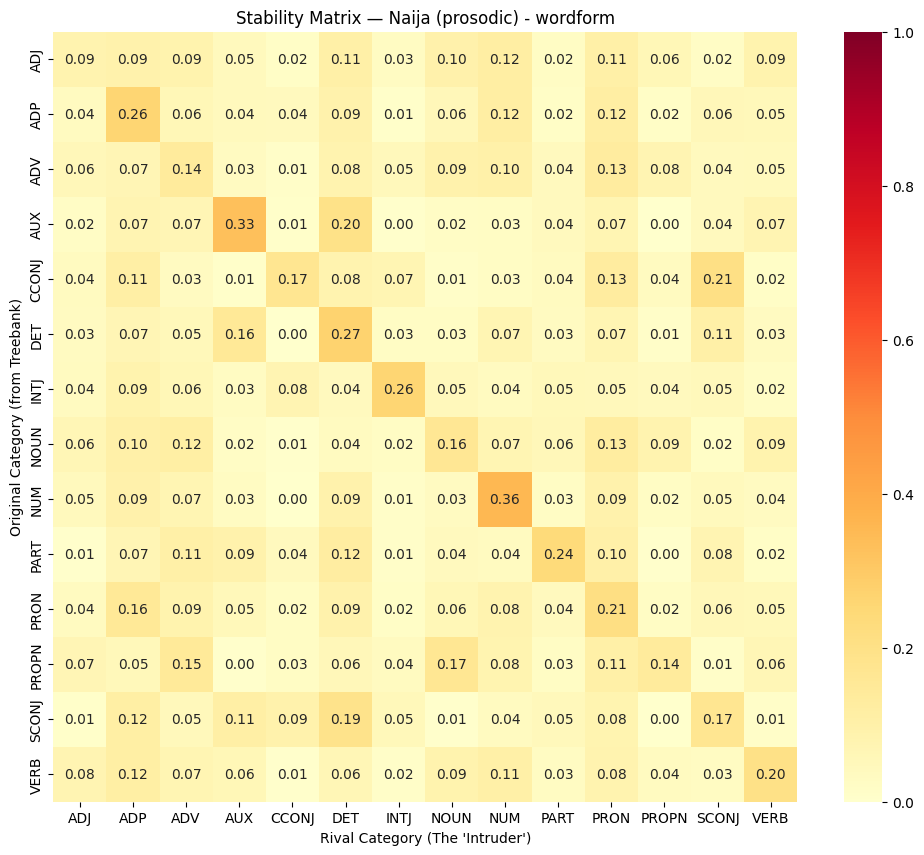

Neighbor,ADJ,ADP,ADV,AUX,CCONJ,DET,INTJ,NOUN,NUM,PART,PRON,PROPN,SCONJ,VERB
Original,,,,,,,,,,,,,,
ADJ,0.085733,0.093249,0.088859,0.045851,0.016952,0.109241,0.029942,0.096267,0.117344,0.024717,0.107692,0.060404,0.021126,0.088740
ADP,0.036106,0.258331,0.059020,0.044085,0.039111,0.091271,0.009749,0.058018,0.120199,0.018993,0.117620,0.019421,0.055450,0.052009
ADV,0.056455,0.069789,0.139620,0.033432,0.014135,0.084166,0.047238,0.093670,0.099549,0.041433,0.132240,0.077624,0.042502,0.045086
AUX,0.019548,0.074334,0.066441,0.330989,0.009325,0.197538,0.004712,0.020376,0.025275,0.042689,0.071027,0.002852,0.042076,0.074348
CCONJ,0.038721,0.110911,0.031999,0.009561,0.168839,0.084173,0.071706,0.014365,0.026771,0.038365,0.131356,0.035534,0.205261,0.018063
DET,0.034765,0.069925,0.052775,0.155288,0.000000,0.271382,0.026867,0.026677,0.072961,0.031852,0.072639,0.013300,0.105600,0.033265
INTJ,0.036195,0.089544,0.061687,0.029169,0.075824,0.040376,0.258959,0.047009,0.037278,0.052285,0.050750,0.041605,0.049929,0.020363
NOUN,0.064418,0.101821,0.116903,0.019852,0.007087,0.035188,0.024300,0.163835,0.073706,0.055255,0.126511,0.085757,0.017773,0.086802
NUM,0.045648,0.094447,0.071654,0.028218,0.000000,0.092092,0.014763,0.032842,0.357436,0.025307,0.090104,0.024471,0.045757,0.035036


In [113]:
# Build a transition matrix for each feature space.
transition_matrices = {
    space: build_transition_matrix(sim, idx2lexunit, category_freqs)
    for space, sim in similarities.items()
}


# Show one — change SPACE to flip view.
SPACE = "prosodic"   # "syntactic", "prosodic", "combined", "prosodic_foot", "prosodic_group", "prosodic_package", "prosodic_period", "prosodic_all_levels"
plot_transition_matrix(
    transition_matrices[SPACE],
    title=f"Stability Matrix — Naija ({SPACE}) - wordform",
    # drop_categories=("X", "SYM"),   # uncomment to hide noise categories
)
transition_matrices[SPACE]


In [114]:
def get_top_bridge_words(scores_dict, original_cat, rival_cat, top_n=100):
    """Words from `original_cat` most pulled toward `rival_cat`."""
    matches = [
        {"word": word, "purity": float(d["purity"]), "entropy": float(d["entropy"])}
        for (word, o_cat), d in scores_dict.items()
        if o_cat == original_cat and d["rival_category"] == rival_cat
    ]
    # Lowest combined score first — least pure, highest entropy.
    matches.sort(key=lambda x: 0.7 * x["purity"] - 0.3 * x["entropy"])
    return [(m["word"], f'{m["purity"]:.2f}', f'{m["entropy"]:.2f}')
            for m in matches[:top_n]]


In [115]:
# ── Pick a feature space and a category pair ──────────────────────────────
SPACE          = "prosodic"        # "syntactic" | "prosodic" | "combined"
ORIGINAL_CAT   = "NOUN"
RIVAL_CAT      = "AUX"

scores = scores_by_space[SPACE]
bridge_words = get_top_bridge_words(scores, ORIGINAL_CAT, RIVAL_CAT)

print(f"Top {ORIGINAL_CAT} → {RIVAL_CAT} bridge words ({SPACE} space):")
print(f"{'Word':<20} {'Purity':>8} {'Entropy':>8}")
for word, purity, ent in bridge_words:
    print(f"{word:<20} {purity:>8} {ent:>8}")


Top NOUN → AUX bridge words (prosodic space):
Word                   Purity  Entropy
Church                   0.00     1.85
mudu                     0.02     1.85
a                        0.00     1.70
step                     0.01     1.66
G                        0.01     1.61
loss                     0.01     1.56
bow                      0.01     1.55
app                      0.00     1.54
bumper                   0.03     1.52
dot                      0.00     1.47
b                        0.01     1.42
shows                    0.09     1.55
uncle                    0.06     1.49
gateman                  0.08     1.51
pain                     0.00     1.34
summer                   0.08     1.50
stew                     0.00     1.27
nursery                  0.05     1.34
wahm                     0.09     1.42
harvest                  0.04     1.25
king                     0.00     1.14
broders                  0.08     1.28
groove                   0.08     1.25
arm               

In [116]:
def get_pulling_features(
    lex_unit, rival_category,
    feature_matrix, similarity_matrix,
    idx2lexunit, lexunit2idx,
    idx2feature, feature2idx,
    feature_mask=None,
    top_k_features=20,
    sim_threshold=0.7, max_neighbours=20,
):
    """Features pulling `lex_unit` toward `rival_category`.

    Score = (unit's coverage on the feature) / (|unit_value − rival_centroid| + ε).
    Features the unit doesn't use at all (zero coverage) score zero — they
    can't be pulling anything.
    """
    unit_idx = lexunit2idx[lex_unit]
    unit_vector = feature_matrix[unit_idx]

    # Top-k neighbours.
    candidate_idx = np.where(similarity_matrix[unit_idx] >= sim_threshold)[0]
    neighbour_indices = sorted(
        [i for i in candidate_idx if i != unit_idx],
        key=lambda i: similarity_matrix[unit_idx][i],
        reverse=True,
    )[:max_neighbours]

    # Rival centroid: median over rival-category neighbours.
    rival_neighbour_indices = [
        i for i in neighbour_indices if idx2lexunit[i][1] == rival_category
    ]
    if not rival_neighbour_indices:
        print(f"No neighbours of category '{rival_category}' found for {lex_unit}.")
        return []
    rival_centroid = np.median(feature_matrix[rival_neighbour_indices], axis=0)

    feature_differences = np.abs(unit_vector - rival_centroid)
    eps = 1e-6
    scores = np.where(
        unit_vector > 0,
        unit_vector / (feature_differences + eps),
        0.0,
    )

    # Restrict scoring to the active feature space. Without this, neighbours
    # are chosen by (e.g.) syntactic similarity but the top-ranked pulling
    # features can come from any column of the full matrix.
    if feature_mask is not None:
        scores = np.where(feature_mask, scores, 0.0)

    top_idx = np.argsort(scores)[::-1][:top_k_features]
    return [
        {
            "feature":    idx2feature[f_idx],
            "unit_value": unit_vector[f_idx],
            "rival_avg":  rival_centroid[f_idx],
            "diff":       feature_differences[f_idx],
            "score":      scores[f_idx],
        }
        for f_idx in top_idx
        if scores[f_idx] > 0
    ]


In [117]:
def get_aggregate_pulling_features(
    scores_dict, original_cat, rival_cat,
    feature_matrix, similarity_matrix,
    idx2lexunit, lexunit2idx,
    idx2feature, feature2idx,
    feature_mask=None,
    top_k_words=10, top_k_features=20,
    sim_threshold=0.7, max_neighbours=20,
):
    """Cross-word aggregate of the pulling features for an `original_cat`
    → `rival_cat` direction.

    A feature appears in the aggregate if it surfaced for at least one bridge
    word. Ranked by how many bridge words it shows up in (robustness), with
    average unit value as a tiebreaker.
    """
    bridge_words = get_top_bridge_words(scores_dict, original_cat, rival_cat,
                                        top_n=top_k_words)
    if not bridge_words:
        print(f"No bridge words found from {original_cat} to {rival_cat}")
        return None

    print(f"Analyzing {len(bridge_words)} bridge words: "
          f"{[w[0] for w in bridge_words]}\n")

    per_feature = {}
    for word, _purity, _entropy in bridge_words:
        lex_unit = (word, original_cat)
        if lex_unit not in lexunit2idx:
            print(f"  WARNING: {lex_unit} not found in lexunit2idx, skipping.")
            continue

        word_features = get_pulling_features(
            lex_unit=lex_unit, rival_category=rival_cat,
            feature_matrix=feature_matrix, similarity_matrix=similarity_matrix,
            idx2lexunit=idx2lexunit, lexunit2idx=lexunit2idx,
            idx2feature=idx2feature, feature2idx=feature2idx,
            feature_mask=feature_mask,
            top_k_features=top_k_features * 2,   # cast wide before aggregating
            sim_threshold=sim_threshold, max_neighbours=max_neighbours,
        )
        for fd in word_features:
            d = per_feature.setdefault(fd["feature"],
                                       {"unit_values": [], "rival_avgs": [], "diffs": []})
            d["unit_values"].append(fd["unit_value"])
            d["rival_avgs"].append(fd["rival_avg"])
            d["diffs"].append(fd["diff"])

    if not per_feature:
        print("No features collected — check bridge words and similarity threshold.")
        return None

    rows = [
        {
            "feature":         fname,
            "count_words":     len(d["unit_values"]),
            "avg_unit_value":  float(np.mean(d["unit_values"])),
            "avg_rival_value": float(np.mean(d["rival_avgs"])),
            "avg_diff":        float(np.mean(d["diffs"])),
            "std_unit_value":  float(np.std(d["unit_values"])),
        }
        for fname, d in per_feature.items()
    ]
    rows.sort(key=lambda r: (r["count_words"], r["avg_unit_value"]), reverse=True)
    return pd.DataFrame(rows[:top_k_features])


In [118]:
# ── Single-word usage ──────────────────────────────────────────────────────
SPACE        = "prosodic"          # "syntactic" | "prosodic" | "combined"
LEX_UNIT     = ("maternelle", "ADJ")
RIVAL_CAT    = "DET"

results = get_pulling_features(
    LEX_UNIT, RIVAL_CAT,
    feature_matrix, similarities[SPACE],
    idx2lexunit, lexunit2idx,
    idx2feature, feature2idx,
    feature_mask=SPACE_MASKS[SPACE],
    top_k_features=20,
)

print(f"Top features pulling {LEX_UNIT} toward {RIVAL_CAT} ({SPACE} space):")
print(f"{'Feature':<55} {'unit':>6}  {'rival':>6}  {'diff':>6}  {'score':>8}")
print("-" * 90)
for r in results:
    print(
        f"{r['feature']:<55} "
        f"{r['unit_value']:>6.3f}  "
        f"{r['rival_avg']:>6.3f}  "
        f"{r['diff']:>6.3f}  "
        f"{r['score']:>8.2f}"
    )
    


KeyError: ('maternelle', 'ADJ')

In [119]:
# ── Aggregate usage (the "defining features" of a directional pull) ───────
SPACE        = "prosodic"           # "syntactic" | "prosodic" | "combined"
ORIGINAL_CAT = "NOUN"
RIVAL_CAT    = "AUX"

df_agg = get_aggregate_pulling_features(
    scores_dict=scores_by_space[SPACE],
    original_cat=ORIGINAL_CAT, rival_cat=RIVAL_CAT,
    feature_matrix=feature_matrix,
    similarity_matrix=similarities[SPACE],
    idx2lexunit=idx2lexunit, lexunit2idx=lexunit2idx,
    idx2feature=idx2feature, feature2idx=feature2idx,
    feature_mask=SPACE_MASKS[SPACE],
    top_k_words=5, top_k_features=20,
)

if df_agg is not None:
    print(df_agg.to_string(index=False))


Analyzing 5 bridge words: ['Church', 'mudu', 'a', 'step', 'G']

                                                              feature  count_words  avg_unit_value  avg_rival_value  avg_diff  std_unit_value
                                     node:X:childSyl1:StepsFromLeft=1            5        0.029267         0.026810  0.004255        0.005820
                                       node:X:nextSyl:StepsFromLeft=1            5        0.029267         0.025097  0.005573        0.005820
                                      node:X:nextSyl:StepsFromRight=1            5        0.029267         0.023134  0.007171        0.005820
                                     node:X:childSyl1:PitchRangeGlo=L            5        0.024368         0.023846  0.003905        0.005995
                                    node:X:childSyl1:StepsFromRight=1            4        0.029089         0.028723  0.006830        0.007513
                                       node:X:nextSyl:PitchRangeGlo=L            4  

In [120]:
def calculate_weighted_stability(transition_matrix, category_counts):
    """Weighted average of the diagonal of the transition matrix.

    transition_matrix : square, row-stochastic, indexed by POS.
    category_counts   : dict / Series mapping POS → token count (or any
                         consistent weight).
    """
    categories = transition_matrix.index
    stability_scores = pd.Series(np.diag(transition_matrix), index=categories)
    weights = pd.Series(category_counts).reindex(categories).fillna(0)
    total_weight = weights.sum()
    if total_weight == 0:
        return 0.0
    return (stability_scores * weights).sum() / total_weight


# WAS for every feature space.
for space, tm in transition_matrices.items():
    was = calculate_weighted_stability(tm, category_freqs)
    print(f"WAS ({space:<9}): {was:.4f}")


WAS (syntactic): 0.5393
WAS (prosodic ): 0.1687
WAS (combined ): 0.3928


In [121]:
def permutation_null(similarity, idx2lexunit, n_permutations=200, seed=0):
    rng = np.random.default_rng(seed)
    pos_labels = np.array([lu[1] for lu in idx2lexunit.values()])
    lemmas     = [lu[0] for lu in idx2lexunit.values()]

    # category_freqs depends only on the count of each label, which is
    # preserved under permutation, so we can compute it once.
    cat_counts = Counter(pos_labels)
    n_total = len(pos_labels)
    cat_freqs = {c: k / n_total for c, k in cat_counts.items()}

    null_matrices = []
    for _ in range(n_permutations):
        shuffled = rng.permutation(pos_labels)
        idx2lex_perm = {i: (lemmas[i], shuffled[i]) for i in range(len(lemmas))}
        m = build_transition_matrix(similarity, idx2lex_perm, cat_freqs)
        null_matrices.append(m)

    # Align all matrices on the same category set
    all_cats = sorted(set().union(*[m.index for m in null_matrices]))
    aligned  = [m.reindex(index=all_cats, columns=all_cats, fill_value=0)
                for m in null_matrices]
    stack    = np.stack([m.values for m in aligned])      # shape (n_perm, k, k)
    return (pd.DataFrame(stack.mean(axis=0), index=all_cats, columns=all_cats),
            pd.DataFrame(stack.std(axis=0),  index=all_cats, columns=all_cats))

null_mean, null_std = permutation_null(similarities["prosodic"], idx2lexunit)
observed = transition_matrices["prosodic"]
z_scores = (observed - null_mean) / null_std.replace(0, np.nan)

In [122]:
print("Z-scores for prosodic transition matrix vs. permutation null:")
print(z_scores)

Z-scores for prosodic transition matrix vs. permutation null:
Neighbor       ADJ       ADP       ADV       AUX     CCONJ       DET  \
Original                                                               
ADJ      -0.322825  2.447226  0.972181 -0.104824 -0.743375  4.264010   
ADP      -3.354939  9.398867 -0.990818 -0.144139  0.561939  2.286578   
ADV      -2.646207  0.590591  4.080172 -0.812444 -0.832406  2.388428   
AUX      -3.014160  0.464074 -0.467299  9.783379 -0.815274  5.183477   
CCONJ    -1.702054  1.251786 -1.175053 -0.999430  3.703734  1.110192   
DET      -2.372008  0.312384 -1.082157  3.805925 -1.015784  7.360502   
INTJ     -3.331916  1.437217 -0.910198 -0.828692  2.105671 -0.223063   
NOUN     -3.164810  3.051335  3.715160 -1.913762 -1.544556 -0.681600   
NUM      -2.218049  1.641227 -0.307011 -0.644504 -1.136455  1.644684   
PART     -3.855554  0.223215  1.276984  1.440797  0.399743  2.447497   
PRON     -4.322259  4.836554  0.723552  0.270935 -0.162406  1.999902   
PR

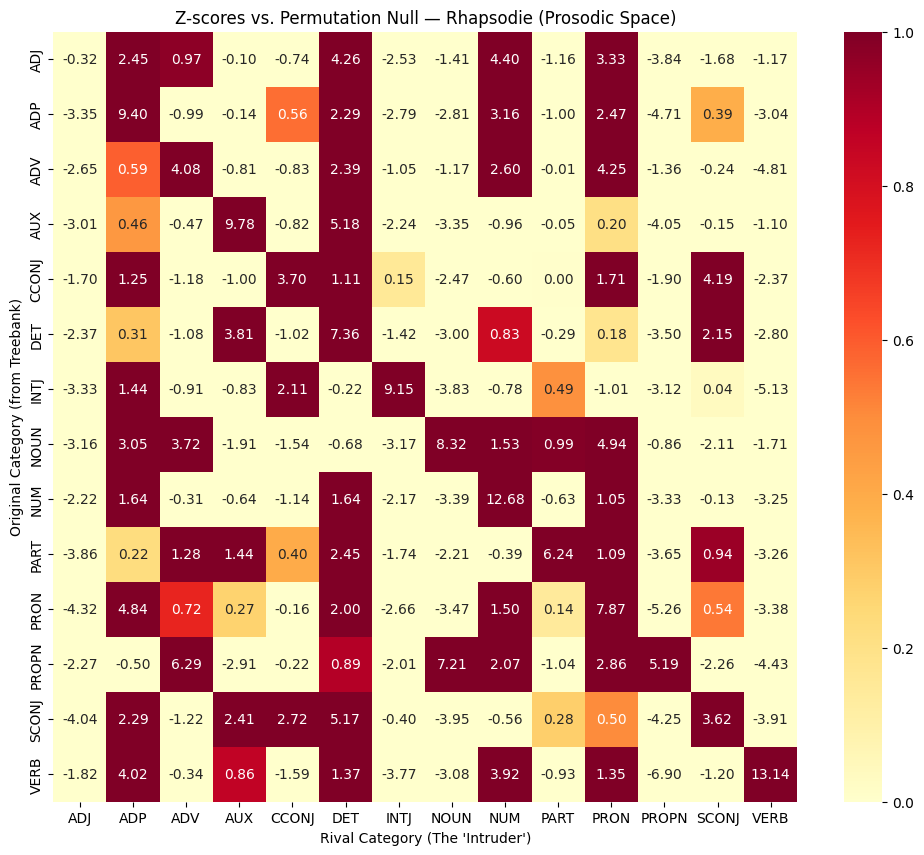

In [123]:
plot_transition_matrix(
    z_scores,
    title="Z-scores vs. Permutation Null — Rhapsodie (Prosodic Space)",
    drop_categories=("X", "SYM"),   # hide noise categories
)